# Xiao_Hongwei_HW5
Name: Hongwei Xiao  
GitHub username: Ga9a  

## 1. Decision trees
### (a) Data and setup
The supplied Acute Inflammations data contain six predictors and two binary
outcomes. I combine the two outcomes into four classes (label powerset).
Here B means bladder inflammation and N means nephritis. A value of 1 means yes.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import KFold, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score
from threadpoolctl import threadpool_limits
from xgboost import XGBRegressor

ROOT = Path('..') if Path('../data/diagnosis.data').exists() else Path('.')
DATA, OUT = ROOT / 'data', ROOT / 'results'
OUT.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style='whitegrid', context='notebook', font_scale=0.8)
pd.set_option('display.precision', 6)
thread_limit = threadpool_limits(limits=1)

features = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing',
            'micturition_pain', 'urethral_burning']
acute = pd.read_csv(DATA / 'diagnosis.data', sep='\t', encoding='utf-16',
                    decimal=',', names=features + ['B', 'N'])
for name in features[1:] + ['B', 'N']:
    acute[name] = acute[name].map({'no': 0, 'yes': 1})
Xa = acute[features]
ya = 2 * acute['B'] + acute['N']
labels = ['B=0,N=0', 'B=0,N=1', 'B=1,N=0', 'B=1,N=1']
assert acute.shape == (120, 8) and not acute.isna().any().any()
print('Data shape:', acute.shape, '| Missing values:', acute.isna().sum().sum())
display(acute.head(3))
display(ya.value_counts().sort_index().rename(index=dict(enumerate(labels))).to_frame('count').T)

Data shape: (120, 8) | Missing values: 0


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,urethral_burning,B,N
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0


,"B=0,N=0","B=0,N=1","B=1,N=0","B=1,N=1"
count,30,31,40,19


### (b) Full tree
The tree is fitted to all 120 observations, as requested. Its accuracy below
is training accuracy, not a test estimate.

Depth: 4, leaves: 6, training accuracy: 1.0000


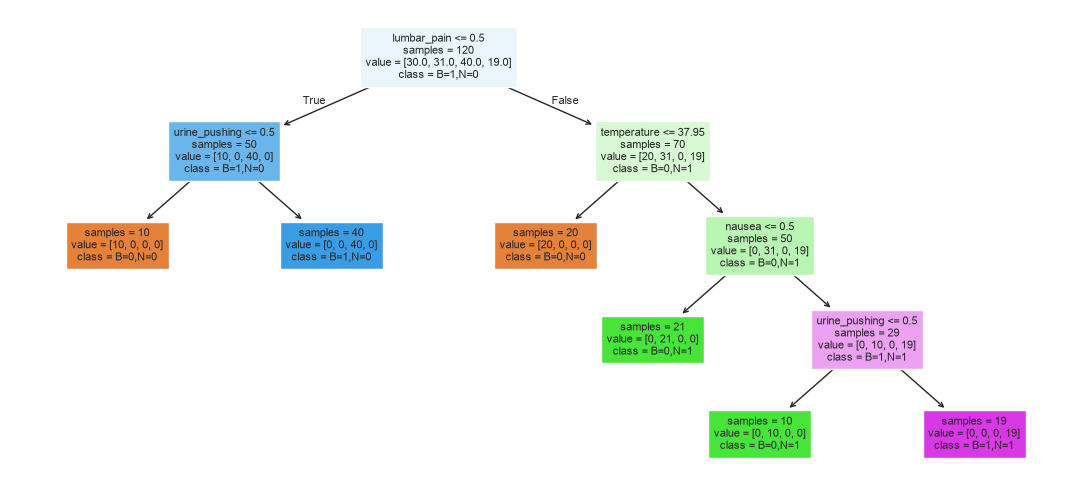

In [2]:
full_tree = DecisionTreeClassifier(random_state=SEED).fit(Xa, ya)
print(f'Depth: {full_tree.get_depth()}, leaves: {full_tree.get_n_leaves()}, '
      f'training accuracy: {full_tree.score(Xa, ya):.4f}')
fig, ax = plt.subplots(figsize=(11, 5))
plot_tree(full_tree, feature_names=features, class_names=labels,
          filled=True, impurity=False, precision=2, fontsize=8, ax=ax)
fig.tight_layout()
fig.savefig(OUT / 'full_tree.png', dpi=180)
plt.show()

### (c) IF-THEN rules
Each root-to-leaf path is one rule. Binary predictors use 0 = no and 1 = yes.

In [3]:
def tree_rules(model):
    tree = model.tree_
    rules = []
    def visit(node, conditions):
        if tree.feature[node] == _tree.TREE_UNDEFINED:
            cls = model.classes_[np.argmax(tree.value[node][0])]
            condition = ' AND '.join(conditions) or 'always'
            rules.append(f'IF {condition} THEN {labels[int(cls)]} '
                         f'(n={tree.n_node_samples[node]})')
            return
        name, cut = features[tree.feature[node]], tree.threshold[node]
        if name == 'temperature':
            left, right = f'{name} <= {cut:.2f}', f'{name} > {cut:.2f}'
        else:
            left, right = f'{name}=no', f'{name}=yes'
        visit(tree.children_left[node], conditions + [left])
        visit(tree.children_right[node], conditions + [right])
    visit(0, [])
    return rules

full_rules = tree_rules(full_tree)
display(Markdown('\n'.join(f'{i}. {r}' for i, r in enumerate(full_rules, 1))))
(OUT / 'full_tree_rules.txt').write_text('\n'.join(full_rules), encoding='utf-8');

1. IF lumbar_pain=no AND urine_pushing=no THEN B=0,N=0 (n=10)
2. IF lumbar_pain=no AND urine_pushing=yes THEN B=1,N=0 (n=40)
3. IF lumbar_pain=yes AND temperature <= 37.95 THEN B=0,N=0 (n=20)
4. IF lumbar_pain=yes AND temperature > 37.95 AND nausea=no THEN B=0,N=1 (n=21)
5. IF lumbar_pain=yes AND temperature > 37.95 AND nausea=yes AND urine_pushing=no THEN B=0,N=1 (n=10)
6. IF lumbar_pain=yes AND temperature > 37.95 AND nausea=yes AND urine_pushing=yes THEN B=1,N=1 (n=19)

### (d) Cost-complexity pruning
I compare the trees along the pruning path using five stratified folds.
For a compact rule set, I choose the smallest tree on this path with mean
cross-validation accuracy of at least 80%. This is an explicit simplicity
tradeoff; I also report the tree with the highest CV accuracy.

,alpha,leaves,depth,train_accuracy,cv_accuracy,cv_se
0,0.000000,6,4,1.000000,0.991667,0.008333
1,0.098167,4,2,0.841667,0.858333,0.025000
2,0.133333,3,2,0.758333,0.758333,0.033333
3,0.182000,2,1,0.591667,0.666667,0.029463
4,0.222917,1,0,0.333333,0.483333,0.061237


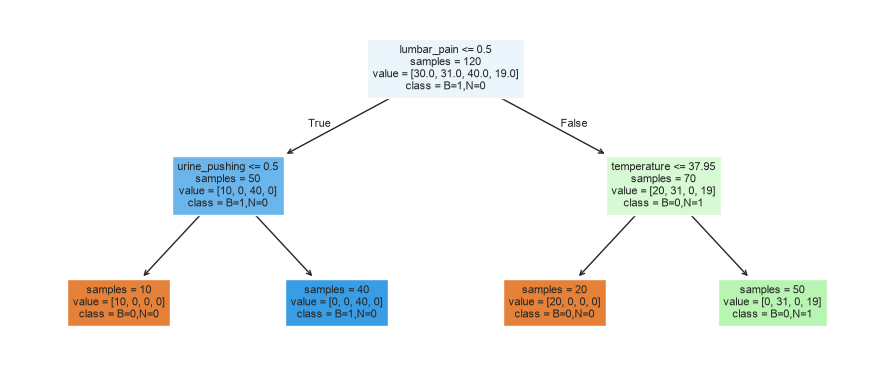

1. IF lumbar_pain=no AND urine_pushing=no THEN B=0,N=0 (n=10)
2. IF lumbar_pain=no AND urine_pushing=yes THEN B=1,N=0 (n=40)
3. IF lumbar_pain=yes AND temperature <= 37.95 THEN B=0,N=0 (n=20)
4. IF lumbar_pain=yes AND temperature > 37.95 THEN B=0,N=1 (n=50)

The compact tree has 4 leaves and depth 2, with CV accuracy 85.83%. The best CV score is 99.17% with 6 leaves. The shorter rules lose accuracy, so the full tree is preferable if prediction accuracy matters more.

In [4]:
tree_cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
alphas_tree = full_tree.cost_complexity_pruning_path(Xa, ya).ccp_alphas
rows = []
for alpha in alphas_tree:
    model = DecisionTreeClassifier(ccp_alpha=alpha, random_state=SEED)
    scores = cross_val_score(model, Xa, ya, cv=tree_cv, scoring='accuracy')
    model.fit(Xa, ya)
    rows.append([alpha, model.get_n_leaves(), model.get_depth(),
                 model.score(Xa, ya), scores.mean(), scores.std(ddof=1) / np.sqrt(5)])
pruning = pd.DataFrame(rows, columns=['alpha', 'leaves', 'depth', 'train_accuracy',
                                    'cv_accuracy', 'cv_se'])
display(pruning)
pruning.to_csv(OUT / 'pruning_path.csv', index=False)
chosen = pruning[pruning.cv_accuracy >= 0.80].sort_values(
    ['leaves', 'cv_accuracy'], ascending=[True, False]).iloc[0]
pruned_tree = DecisionTreeClassifier(ccp_alpha=chosen.alpha, random_state=SEED).fit(Xa, ya)
fig, ax = plt.subplots(figsize=(9, 3.8))
plot_tree(pruned_tree, feature_names=features, class_names=labels,
          filled=True, impurity=False, precision=2, fontsize=8, ax=ax)
fig.tight_layout()
fig.savefig(OUT / 'pruned_tree.png', dpi=180)
plt.show()
pruned_rules = tree_rules(pruned_tree)
display(Markdown('\n'.join(f'{i}. {r}' for i, r in enumerate(pruned_rules, 1))))
(OUT / 'pruned_tree_rules.txt').write_text('\n'.join(pruned_rules), encoding='utf-8')
best = pruning.loc[pruning.cv_accuracy.idxmax()]
display(Markdown(f'The compact tree has {int(chosen.leaves)} leaves and depth '
                 f'{int(chosen.depth)}, with CV accuracy {chosen.cv_accuracy:.2%}. '
                 f'The best CV score is {best.cv_accuracy:.2%} with '
                 f'{int(best.leaves)} leaves. The shorter rules lose accuracy, '
                 'so the full tree is preferable if prediction accuracy matters more.'))

## 2. The LASSO and boosting for regression
### (a)-(b) Split and missing values
The target is `ViolentCrimesPerPop`. The first 1,495 rows are training data;
the remaining 499 rows are test data. I drop `state`, `county`, `community`,
`communityname`, and `fold`, which the description marks as nonpredictive.

Missing values are replaced with training medians. During cross-validation,
the imputer and any scaler/PCA are fitted separately inside each training fold.
I use training data for the descriptive plots as well.

In [5]:
names = [line.split()[1] for line in (DATA / 'communities.names').read_text().splitlines()
         if line.startswith('@attribute')]
crime = pd.read_csv(DATA / 'communities.data', names=names, na_values='?')
target = 'ViolentCrimesPerPop'
excluded = ['state', 'county', 'community', 'communityname', 'fold']
X = crime.drop(columns=excluded + [target]).astype(float)
y = crime[target].astype(float)
X_train, X_test = X.iloc[:1495].copy(), X.iloc[1495:].copy()
y_train, y_test = y.iloc[:1495].copy(), y.iloc[1495:].copy()
assert crime.shape == (1994, 128) and X.shape[1] == 122
assert y.notna().all() and not X_train.isna().all().any()
imputer = SimpleImputer(strategy='median', keep_empty_features=True)
X_desc = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns)
print('Training:', X_train.shape, '| Test:', X_test.shape)
print('Missing predictor values: train =', X_train.isna().sum().sum(),
      ', test =', X_test.isna().sum().sum())
missing = X_train.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].head(5).to_frame('training_missing'))
pd.DataFrame({'index': np.arange(1, 123), 'feature': X.columns}).to_csv(
    OUT / 'feature_order.csv', index=False)

Training: (1495, 122) | Test: (499, 122)
Missing predictor values: train = 27633 , test = 9218


,training_missing
LemasSwFTFieldPerPop,1256
LemasSwFTFieldOps,1256
RacialMatchCommPol,1256
PctPolicWhite,1256
LemasSwornFT,1256


### (c) Correlation matrix
The matrix contains all 122 predictors after training-median imputation.
The axes use feature indices; `results/feature_order.csv` gives the names.

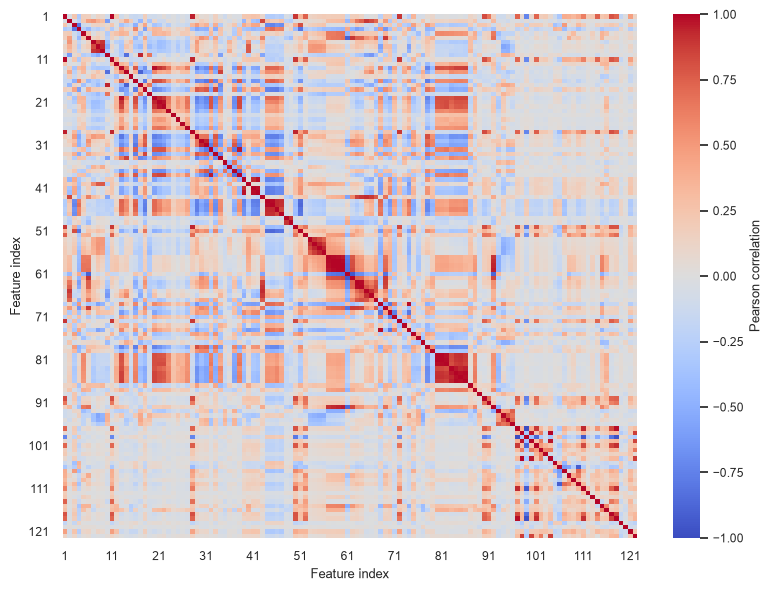

In [6]:
corr = X_desc.corr()
corr.to_csv(OUT / 'feature_correlations.csv')
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, center=0,
            xticklabels=False, yticklabels=False, ax=ax,
            cbar_kws={'label': 'Pearson correlation'})
ticks = np.arange(0, 122, 10)
ax.set_xticks(ticks + 0.5, labels=ticks + 1)
ax.set_yticks(ticks + 0.5, labels=ticks + 1, rotation=0)
ax.set(xlabel='Feature index', ylabel='Feature index')
fig.tight_layout()
fig.savefig(OUT / 'correlation_matrix.png', dpi=180)
plt.show()

The blocks of strong positive and negative correlations show that many
predictors overlap. That can make least-squares coefficients unstable and
gives a reason to compare regularized models.

### (d) Coefficient of variation
I calculate CV = sample standard deviation / mean on the imputed training
data. A zero mean would make CV undefined. The complete table is saved as
`results/feature_cv.csv`; the largest 11 values are displayed below.

In [7]:
variation = pd.DataFrame({'mean': X_desc.mean(), 'sample_sd': X_desc.std(ddof=1)})
variation['CV'] = variation.sample_sd / variation['mean'].replace(0, np.nan)
variation = variation.sort_values('CV', ascending=False)
variation.to_csv(OUT / 'feature_cv.csv', index_label='feature')
top_features = variation['CV'].dropna().head(int(np.sqrt(128))).index.tolist()
assert len(top_features) == 11
display(variation.loc[top_features])
print('Features calculated:', len(variation), '| Undefined CV:', variation.CV.isna().sum())

,mean,sample_sd,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461


Features calculated: 122 | Undefined CV: 0


### (e) Scatter plots and box plots
I use the 11 highest-CV predictors. Each scatter plot compares one predictor
with the crime target; the box plots show the predictors' distributions.

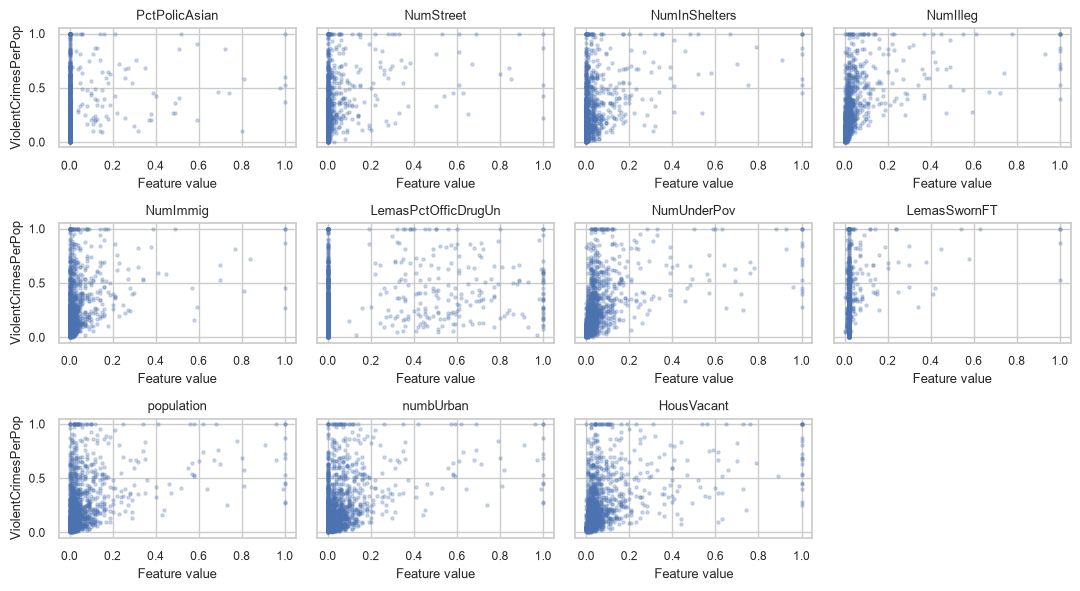

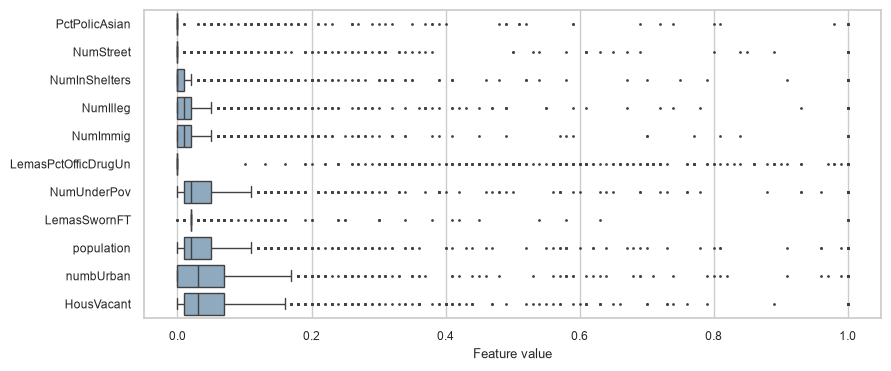

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(11, 6), sharey=True)
for ax, name in zip(axes.flat, top_features):
    ax.scatter(X_desc[name], y_train.to_numpy(), s=5, alpha=0.25, rasterized=True)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel('Feature value')
for ax in axes[:, 0]:
    ax.set_ylabel('ViolentCrimesPerPop')
axes.flat[-1].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / 'top_cv_scatter.png', dpi=180)
plt.show()
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.boxplot(data=X_desc[top_features], orient='h', fliersize=1, ax=ax, color='#87abc7')
ax.set(xlabel='Feature value', ylabel='')
fig.tight_layout()
fig.savefig(OUT / 'top_cv_boxplots.png', dpi=180)
plt.show()

Several high-CV variables have many values near zero and a long upper tail.
High CV measures relative spread, not predictive importance. The scatter plots
can suggest associations, but they do not establish statistical significance:
they do not control for the other predictors or provide a hypothesis test.

### (f) Least squares
I report mean squared error (MSE) on the normalized crime target. All model
choices below use the training set only, with the same five shuffled CV folds.

In [9]:
cv = KFold(5, shuffle=True, random_state=SEED)
results, predictions, searches = [], {}, {}

def regression_pipeline(model, standardize=False, pca=False):
    steps = [('imputer', SimpleImputer(strategy='median', keep_empty_features=True))]
    if standardize:
        steps.append(('scaler', StandardScaler()))
    if pca:
        steps.append(('pca', PCA(svd_solver='full')))
    return Pipeline(steps + [('model', model)])

def record(name, model, settings, cv_mse=np.nan):
    pred = model.predict(X_test)
    predictions[name] = pred
    row = {'model': name, 'settings': settings, 'CV_MSE': cv_mse,
           'test_MSE': mean_squared_error(y_test, pred),
           'test_RMSE': np.sqrt(mean_squared_error(y_test, pred)),
           'test_R2': r2_score(y_test, pred)}
    results.append(row)
    display(pd.DataFrame([row]).set_index('model'))

def tune(name, pipeline, grid):
    search = GridSearchCV(pipeline, grid, cv=cv, scoring='neg_mean_squared_error',
                          n_jobs=1, error_score='raise')
    search.fit(X_train, y_train)
    searches[name] = search
    pd.DataFrame(search.cv_results_).to_csv(OUT / f'{name}_cv.csv', index=False)
    return search

ols = regression_pipeline(LinearRegression()).fit(X_train, y_train)
record('OLS', ols, 'No regularization')

,settings,CV_MSE,test_MSE,test_RMSE,test_R2
model,,,,,
OLS,No regularization,NaN,0.017966,0.134038,0.622204


### (g) Ridge regression
I standardize within each CV fold and search 46 penalty values from
10^-4 to 10^5. The chosen value minimizes mean validation MSE.

In [10]:
ridge = tune('Ridge', regression_pipeline(Ridge(), standardize=True),
             {'model__alpha': np.logspace(-4, 5, 46)})
record('Ridge', ridge.best_estimator_, f'alpha={ridge.best_params_["model__alpha"]:.6g}',
       -ridge.best_score_)

,settings,CV_MSE,test_MSE,test_RMSE,test_R2
model,,,,,
Ridge,alpha=158.489,0.019738,0.017343,0.131694,0.635304


### (h) LASSO, without and with standardization
The supplied predictors are already normalized, but their standard deviations
still differ. I compare the original scale with unit-variance scaling and
search 41 penalties from 10^-5 to 1. A coefficient is selected when it is nonzero.

In [11]:
selected_sets = {}
for name, standardize in [('LASSO_raw', False), ('LASSO_scaled', True)]:
    search = tune(name, regression_pipeline(
        Lasso(max_iter=100000, tol=1e-6), standardize=standardize),
        {'model__alpha': np.logspace(-5, 0, 41)})
    coef = search.best_estimator_.named_steps['model'].coef_
    selected = X.columns[coef != 0].tolist()
    selected_sets[name] = selected
    pd.DataFrame({'feature': X.columns, 'coefficient': coef,
                  'selected': coef != 0}).to_csv(OUT / f'{name}_coefficients.csv', index=False)
    record(name, search.best_estimator_,
           f'alpha={search.best_params_["model__alpha"]:.6g}; {len(selected)} selected',
           -search.best_score_)
    display(Markdown(f'**{name}: {len(selected)} selected variables**\n\n' + ', '.join(selected)))
raw_mse, scaled_mse = results[-2]['test_MSE'], results[-1]['test_MSE']
display(Markdown(f'Test MSE is {raw_mse:.6f} without standardization and '
                 f'{scaled_mse:.6f} with it. '
                 + ('Standardization lowers' if scaled_mse < raw_mse else 'Standardization raises')
                 + ' the test MSE in this split. Scaling changes how strongly '
                 'the L1 penalty acts on each predictor.'))

,settings,CV_MSE,test_MSE,test_RMSE,test_R2
model,,,,,
LASSO_raw,alpha=0.000133352; 76 selected,0.019524,0.017604,0.132678,0.629831


**LASSO_raw: 76 selected variables**

racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec5, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctBornSameState, PctSameCity85, LemasSwFTFieldPerPop, PolicReqPerOffic, RacialMatchCommPol, PctPolicBlack, PctPolicHisp, PctPolicAsian, NumKindsDrugsSeiz, PolicAveOTWorked, LandArea, PopDens, PctUsePubTrans, PolicCars, LemasPctPolicOnPatr, LemasGangUnitDeploy, LemasPctOfficDrugUn

,settings,CV_MSE,test_MSE,test_RMSE,test_R2
model,,,,,
LASSO_scaled,alpha=0.000562341; 75 selected,0.019668,0.017748,0.133222,0.626791


**LASSO_scaled: 75 selected variables**

racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PersPerOwnOccHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctSameCity85, LemasSwFTFieldPerPop, LemasTotalReq, PolicReqPerOffic, RacialMatchCommPol, PctPolicBlack, PctPolicHisp, PctPolicAsian, OfficAssgnDrugUnits, NumKindsDrugsSeiz, PolicAveOTWorked, LandArea, PopDens, PctUsePubTrans, PolicCars, LemasPctPolicOnPatr, LemasGangUnitDeploy

Test MSE is 0.017604 without standardization and 0.017748 with it. Standardization raises the test MSE in this split. Scaling changes how strongly the L1 penalty acts on each predictor.

### (i) Principal component regression
I standardize the predictors, fit PCA, and regress on its scores. The number
of components is selected from all integers 1 through 122 using five-fold CV.
PCA is refitted inside each fold.

In [12]:
pcr = tune('PCR', regression_pipeline(LinearRegression(), standardize=True, pca=True),
           {'pca__n_components': list(range(1, X_train.shape[1] + 1))})
record('PCR', pcr.best_estimator_, f'M={pcr.best_params_["pca__n_components"]}',
       -pcr.best_score_)

,settings,CV_MSE,test_MSE,test_RMSE,test_R2
model,,,,,
PCR,M=60,0.02021,0.01835,0.13546,0.614143


### (j) L1-regularized gradient boosting
I use XGBoost's tree booster with `reg_alpha` selected by CV. The other
settings are fixed: 400 trees, depth 3, and learning rate 0.05. In XGBoost,
this L1 penalty acts on leaf weights; it does not fit a separate LASSO
regression inside every node.

In [13]:
xgb = XGBRegressor(objective='reg:squarederror', booster='gbtree',
                   n_estimators=400, max_depth=3, learning_rate=0.05,
                   subsample=1.0, colsample_bytree=1.0, reg_lambda=1.0,
                   tree_method='hist', n_jobs=1, random_state=SEED)
boost = tune('XGBoost', regression_pipeline(xgb),
             {'model__reg_alpha': [0, 0.001, 0.01, 0.1, 0.3, 1, 3, 10, 30, 100]})
record('XGBoost', boost.best_estimator_,
       f'alpha={boost.best_params_["model__reg_alpha"]:.6g}', -boost.best_score_)

comparison = pd.DataFrame(results).set_index('model')
comparison.to_csv(OUT / 'model_comparison.csv')
pd.DataFrame({'actual': y_test.to_numpy(), **predictions}).to_csv(
    OUT / 'test_predictions.csv', index=False)
display(comparison)
winner = comparison.test_MSE.idxmin()
display(Markdown(f'{winner} has the lowest test MSE in this comparison '
                 f'({comparison.loc[winner, "test_MSE"]:.6f}). '
                 'The test set was used only for the final error reports, '
                 'not for choosing the tuning parameters.'))

,settings,CV_MSE,test_MSE,test_RMSE,test_R2
model,,,,,
XGBoost,alpha=0.1,0.019942,0.01638,0.127985,0.655554


,settings,CV_MSE,test_MSE,test_RMSE,test_R2
model,,,,,
OLS,No regularization,NaN,0.017966,0.134038,0.622204
Ridge,alpha=158.489,0.019738,0.017343,0.131694,0.635304
LASSO_raw,alpha=0.000133352; 76 selected,0.019524,0.017604,0.132678,0.629831
LASSO_scaled,alpha=0.000562341; 75 selected,0.019668,0.017748,0.133222,0.626791
PCR,M=60,0.020210,0.018350,0.135460,0.614143
XGBoost,alpha=0.1,0.019942,0.016380,0.127985,0.655554


XGBoost has the lowest test MSE in this comparison (0.016380). The test set was used only for the final error reports, not for choosing the tuning parameters.

## Sources
- [UCI Acute Inflammations](https://archive.ics.uci.edu/dataset/184/acute+inflammations).
  The supplied data were created by J. Czerniak; the dataset cites Czerniak and
  Zarzycki (2003), *Application of rough sets in the presumptive diagnosis of urinary system diseases*.
- [UCI Communities and Crime](https://archive.ics.uci.edu/dataset/183/communities+and+crime).
  Data and column descriptions are included in `data/`.
- [Scikit-learn tree pruning](https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html).
- [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html).